In [ ]:
# Data dictionary: https://byui-cse.github.io/cse450-course/module-04/bikes-dictionary.txt
# Data: https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv
# Load some test data
import polars as pl
df = pl.read_csv('https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes.csv', infer_schema_length=None)
df.describe()

statistic,dteday,hr,casual,registered,temp_c,feels_like_c,hum,windspeed,weathersit,season,holiday,workingday
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""112475""",112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0,112475.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",null,11.501098,90.434612,249.193625,15.376487,14.659325,0.636624,13.100614,1.405441,2.495799,0.0303,0.684312
"""std""",null,6.921864,128.655621,258.267544,9.749467,11.428324,0.190328,7.8576,0.68345,1.101152,0.171412,0.464791
"""min""","""1/1/2011""",0.0,0.0,0.0,-14.7,-24.0,0.0889,0.0,1.0,1.0,0.0,0.0
"""25%""",null,6.0,7.0,48.0,7.6,5.4,0.4841,7.7,1.0,2.0,0.0,0.0
"""50%""",null,12.0,36.0,180.0,16.0,16.0,0.6409,12.2,1.0,2.0,0.0,1.0
"""75%""",null,18.0,122.0,360.0,23.5,23.5,0.7988,17.5,2.0,3.0,0.0,1.0
"""max""","""9/9/2023""",23.0,1244.0,1702.0,40.5,49.6,1.0,69.8,4.0,4.0,1.0,1.0


In [ ]:
# Import the libraries we need
# TensorFlow and tf.keras
import tensorflow as tf
from tensorflow import keras
from keras.layers import Dense, Dropout, Normalization

import numpy as np

%pip install lets-plot
from lets_plot import *
LetsPlot.setup_html()
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 43.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [lets-plot]


In [ ]:
import datetime as dt

def thanksgiving(y):
    first = dt.date(y, 11, 1)
    first_thu = first + dt.timedelta(days=(3 - first.weekday()) % 7)  # Monday = 0
    return first_thu + dt.timedelta(weeks=3)

def clip_off(n, lo, hi):
    return str(n) if lo <= n <= hi else "none"

def holiday_lookup(dates):
    rows = []
    for d in dates:
        tg = (d - thanksgiving(d.year)).days
        xm = min(((d - dt.date(y, 12, 25)).days for y in (d.year - 1, d.year)), key=abs)
        rows.append((d, "tg_" + clip_off(tg, -3, 4), "xm_" + clip_off(xm, -3, 7)))
    return pl.DataFrame(rows, schema=["date", "tg_off", "xm_off"], orient="row")

categorical_cols = ["month", "weekday", "weathersit", "season", "year", "hr"]

START = df["dteday"].str.to_date("%m/%d/%Y").min()   # fixed training start date
RECENT = pl.date(2022, 1, 1)                          # start of the recent growth period


def prep(df):
    date = pl.col("dteday").str.to_date("%m/%d/%Y")
    lookup = holiday_lookup(df.select(date.alias("d"))["d"].unique().to_list())
    return (
        df.with_columns(
            date=date,
            days=(date - pl.lit(START)).dt.total_days(),
            recent_days=(date - RECENT).dt.total_days().clip(lower_bound=0),
            covid=((date >= pl.date(2020, 3, 1)) & (date <= pl.date(2021, 12, 31))).cast(pl.Int8),
            month=date.dt.month(),
            weekday=date.dt.weekday(),
            # Converts temp and feels like into Fahrenheit
            temp_f=pl.col('temp_c') * 1.8 + 32,
            feels_like_f=pl.col('feels_like_c') * 1.8 + 32,
        )
        .join(lookup, on="date", how="left")
        .drop("dteday", "date", "casual", "registered", "total", strict=False)
        .to_dummies(columns=categorical_cols + ["tg_off", "xm_off"])
    )

X_df = prep(df)
FEATURES = X_df.columns   # the model expects exactly these columns, in this order
X = X_df.to_numpy().astype("float32")
y = (df["casual"] + df["registered"]).to_numpy().astype("float32")


In [ ]:

# Recency weights: oldest rows get 0.5, newest rows get 1.0 (raise the 0.5 floor for less emphasis)
days_all = (df["dteday"].str.to_date("%m/%d/%Y") - START).dt.total_days().to_numpy()
w = (0.5 + 0.5 * days_all / days_all.max()).astype("float32")

X_train, X_val, y_train, y_val, w_train, w_val = train_test_split(
    X, y, w, test_size=0.2, random_state=48
)

# min/max scaling lives inside the model, so a holdout is scaled with the training min/max
x_min = X_train.min(axis=0)
x_rng = X_train.max(axis=0) - x_min
x_rng[x_rng == 0] = 1.0   # avoid dividing by zero on constant columns
norm = keras.layers.Rescaling(scale=1.0 / x_rng, offset=-x_min / x_rng)
y_min, y_max = y_train.min(), y_train.max()
y_norm = keras.layers.Rescaling(scale=y_max - y_min, offset=y_min)   # inverse: back to riders

model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    norm,
    Dense(150, activation="relu"),
    Dropout(0.4),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1),
    y_norm,
])
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0008),
              loss="mse", metrics=["mae", keras.metrics.R2Score(name="r2")])
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=7,
                                           restore_best_weights=True)
history = model.fit(
    X_train, y_train.reshape(-1, 1),
    sample_weight=w_train,
    validation_data=(X_val, y_val.reshape(-1, 1)),
    epochs=30, batch_size=80, callbacks=[early_stop],
)
hist = pl.DataFrame(history.history)


Epoch 1/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 15s 11ms/step - loss: 46884.9531 - mae: 171.3856 - r2: 0.4807 - val_loss: 18751.0605 - val_mae: 99.4833 - val_r2: 0.8373
Epoch 2/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 18375.6328 - mae: 108.4745 - r2: 0.7955 - val_loss: 12601.0381 - val_mae: 80.2204 - val_r2: 0.8907
Epoch 3/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 14039.4180 - mae: 94.3192 - r2: 0.8450 - val_loss: 9817.3086 - val_mae: 69.1267 - val_r2: 0.9148
Epoch 4/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 12160.0410 - mae: 86.7975 - r2: 0.8663 - val_loss: 9072.5322 - val_mae: 68.0905 - val_r2: 0.9213
Epoch 5/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 11132.2627 - mae: 82.7736 - r2: 0.8779 - val_loss: 8944.0156 - val_mae: 67.2568 - val_r2: 0.9224
Epoch 6/30
1125/1125 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 10465.7363 - mae: 80.2207 - r2: 0.8852 - val_loss: 8680.3643 - val_mae: 66.9961 - val_r2: 0.9247
Epoch 7/30
1125/1125 ━━━━━━━━━━━━━━━━━━

In [ ]:
hist = hist.with_row_index()
mse_hist = (hist.select('index', 'loss', 'val_loss')
    .unpivot(index='index', variable_name='metric', value_name='mse')
    .with_columns(pl.col('metric').replace({'loss': 'training error', 'val_loss': 'validation error'})))

pred = np.maximum(model.predict(X_val).flatten(), 0)

mae = np.abs(pred - y_val).mean()
print(f"Average error: {mae:.1f} riders")

703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Average error: 48.1 riders


In [ ]:
def align(df, features):
    """Match a prepped dataframe to the training columns, in the same order."""
    # Add dummy columns that exist in training but not in this data (e.g. a month missing from the mini holdout)
    missing = [c for c in features if c not in df.columns]
    if missing:
        df = df.with_columns([pl.lit(0).alias(c) for c in missing])
    # Drop any extra columns and put the rest in training order
    return df.select(features)

# holdout testing (biking dataset)
test_raw = pl.read_csv(
    "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes_december.csv"
)

# Same feature prep as training, then match the training columns and order
test_df = align(prep(test_raw), FEATURES)
X_test = test_df.to_numpy().astype("float32")

# Scaling happens inside the model, so no separate transform step
predictions_holdout = np.maximum(np.round(model.predict(X_test).flatten()), 0)

predictions_df = pl.DataFrame({"predictions": predictions_holdout})
predictions_df.write_csv("team3-module4-predictions.csv")

46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


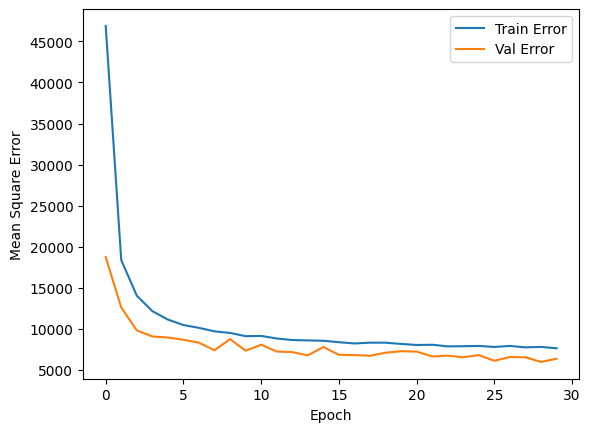

In [ ]:
def plot_history():
    plt.figure()
    plt.xlabel('Epoch')
    plt.ylabel('Mean Square Error')
    plt.plot(hist['index'], hist['loss'], label='Train Error')
    plt.plot(hist['index'], hist['val_loss'], label='Val Error')
    plt.legend()
    plt.show()

plot_history()

In [ ]:
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

pred = np.maximum(model.predict(X_val).flatten(), 0)

mse = mean_squared_error(y_val, pred)
rmse = root_mean_squared_error(y_val, pred)
mae = np.abs(pred - y_val).mean()
r2 = r2_score(y_val, pred)

print(f"MSE:  {mse:.1f}")
print(f"RMSE: {rmse:.1f} riders")
print(f"MAE:  {mae:.1f} riders")
print(f"R2:   {r2:.3f}")

703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
MSE:  5972.7
RMSE: 77.3 riders
MAE:  48.1 riders
R2:   0.948


In [ ]:
monthly = (df.with_columns(date=pl.col("dteday").str.to_date("%m/%d/%Y"),
                           total=pl.col("casual") + pl.col("registered"))
             .with_columns(month_start=pl.col("date").dt.truncate("1mo"))
             .group_by("month_start").agg(pl.col("total").mean().alias("mean_riders"))
             .sort("month_start"))

(ggplot(monthly, aes("month_start", "mean_riders"))
 + geom_line()
 + geom_point(size=2)
 + ggtitle("Mean riders per hour, by month"))

703/703 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


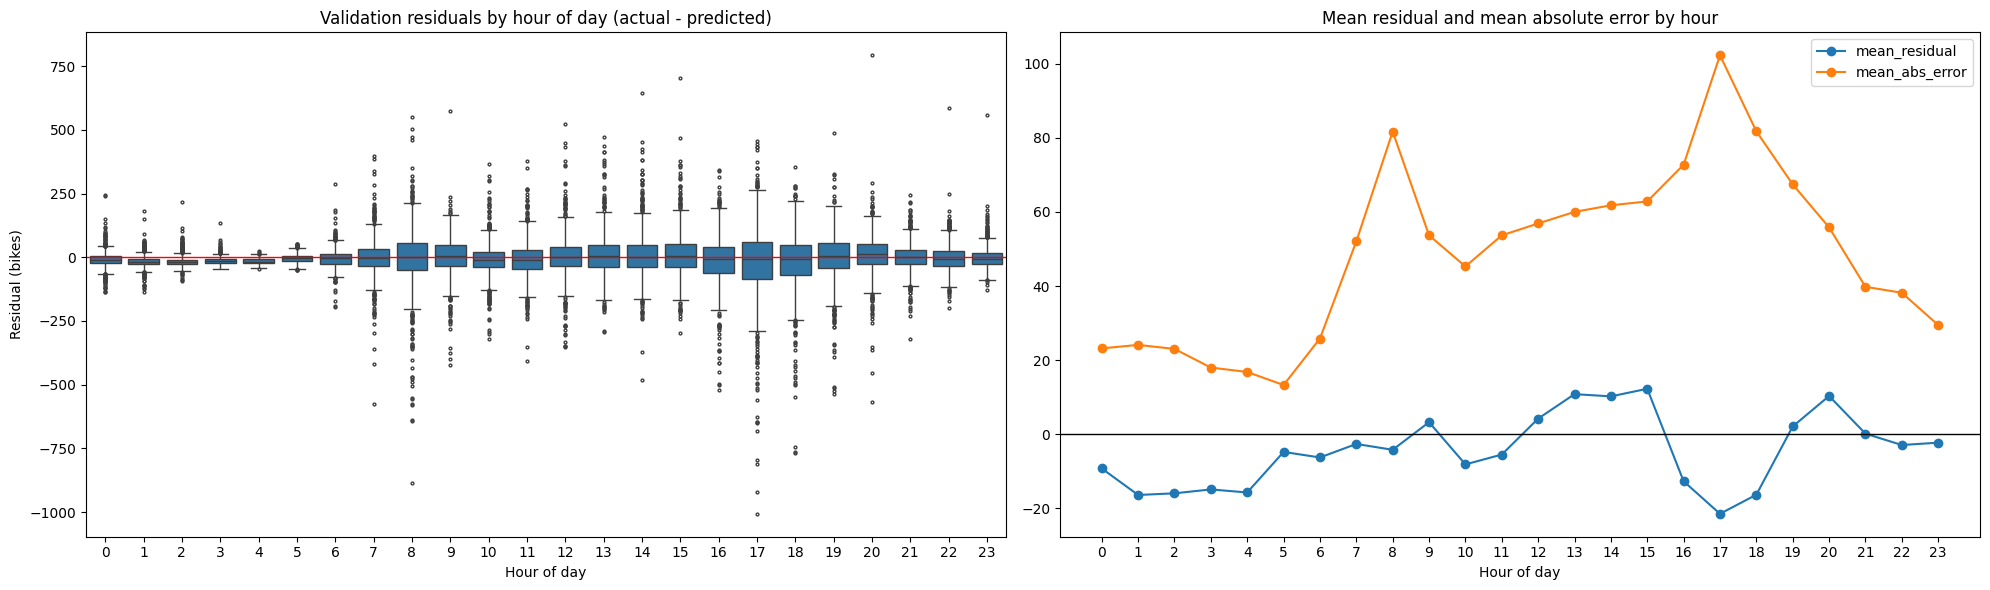

In [ ]:
import seaborn as sns

# hour for each validation row (same split as X_val / y_val)
hr_all = df["hr"].to_numpy()
_, hr_val = train_test_split(hr_all, test_size=0.2, random_state=48)

pred = np.maximum(model.predict(X_val).flatten(), 0)   # in riders (use np.expm1 first if you trained on log)
res = pl.DataFrame({
    "hour": hr_val.astype(int),
    "actual": y_val,            # in riders (use np.expm1(y_val) if you trained on log)
    "predictions": pred,
}).with_columns(residual=pl.col("actual") - pl.col("predictions"))

pdf = res.to_pandas()
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

sns.boxplot(data=pdf, x="hour", y="residual", ax=axes[0], color="tab:blue", fliersize=2)
axes[0].axhline(0, color="red", lw=1)
axes[0].set_title("Validation residuals by hour of day (actual - predicted)")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Residual (bikes)")

by_hour = pdf.groupby("hour")["residual"].agg(
    mean_residual="mean",
    mean_abs_error=lambda r: r.abs().mean(),
)
by_hour.plot(ax=axes[1], marker="o")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_title("Mean residual and mean absolute error by hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_xticks(range(24))

plt.tight_layout()
plt.show()

In [ ]:
import datetime as dt

daily = (df.with_columns(date=pl.col("dteday").str.to_date("%m/%d/%Y"),
                         total=pl.col("casual") + pl.col("registered"))
           .group_by("date").agg(pl.col("total").sum()).sort("date"))
tot = dict(zip(daily["date"].to_list(), daily["total"].to_list()))

def thanksgiving(y):
    first = dt.date(y, 11, 1)
    first_thu = first + dt.timedelta(days=(3 - first.weekday()) % 7)   # python: Monday = 0
    return first_thu + dt.timedelta(weeks=3)

holidays = {"thanksgiving": thanksgiving, "christmas": lambda y: dt.date(y, 12, 25)}

rows = []
for name, fn in holidays.items():
    for y in range(2011, 2023):
        h = fn(y)
        for off in range(-3, 5):
            day = h + dt.timedelta(days=off)
            base = [tot[day + dt.timedelta(weeks=k)] for k in (-3, -2, 2, 3)
                    if day + dt.timedelta(weeks=k) in tot]
            if day in tot and len(base) >= 3:
                rows.append((name, y, off, tot[day] / (sum(base) / len(base))))

r = pl.DataFrame(rows, schema=["holiday", "year", "offset", "ratio"], orient="row")
print(r.group_by(["holiday", "offset"])
       .agg(median=pl.col("ratio").median(), low=pl.col("ratio").min(),
            high=pl.col("ratio").max())
       .sort(["holiday", "offset"]))

shape: (16, 5)
┌──────────────┬────────┬──────────┬──────────┬──────────┐
│ holiday      ┆ offset ┆ median   ┆ low      ┆ high     │
│ ---          ┆ ---    ┆ ---      ┆ ---      ┆ ---      │
│ str          ┆ i64    ┆ f64      ┆ f64      ┆ f64      │
╞══════════════╪════════╪══════════╪══════════╪══════════╡
│ christmas    ┆ -3     ┆ 0.825076 ┆ 0.197781 ┆ 0.98003  │
│ christmas    ┆ -2     ┆ 0.598075 ┆ 0.227363 ┆ 1.104185 │
│ christmas    ┆ -1     ┆ 0.378718 ┆ 0.162196 ┆ 0.556049 │
│ christmas    ┆ 0      ┆ 0.254649 ┆ 0.15522  ┆ 0.527314 │
│ christmas    ┆ 1      ┆ 0.402173 ┆ 0.089089 ┆ 1.044809 │
│ …            ┆ …      ┆ …        ┆ …        ┆ …        │
│ thanksgiving ┆ 0      ┆ 0.401865 ┆ 0.203426 ┆ 1.027836 │
│ thanksgiving ┆ 1      ┆ 0.641317 ┆ 0.368308 ┆ 0.98553  │
│ thanksgiving ┆ 2      ┆ 0.726509 ┆ 0.285605 ┆ 1.287239 │
│ thanksgiving ┆ 3      ┆ 0.806863 ┆ 0.304432 ┆ 1.179882 │
│ thanksgiving ┆ 4      ┆ 0.979817 ┆ 0.542756 ┆ 1.095467 │
└──────────────┴────────┴──────────┴─────

In [ ]:
import polars as pl

test_raw = pl.read_csv(
    "https://raw.githubusercontent.com/byui-cse/cse450-course/master/data/bikes_december.csv"
)
preds = pl.read_csv("team3-module4-predictions.csv")

holdout_plot = (
    test_raw
    .select(
        (pl.col("dteday").str.to_date("%m/%d/%Y").cast(pl.Datetime)
         + pl.duration(hours=pl.col("hr"))).alias("time")
    )
    .with_columns(preds["predictions"].alias("pred"))
    .sort("time")
    .with_columns(pl.col("time").dt.strftime("%b %Y").alias("month"))
)

print(holdout_plot.height, holdout_plot["time"].n_unique())

1465 1464


In [ ]:
daily_mean = pl.concat([hist_day, pred_day]).sort("date")

(ggplot(daily_mean, aes(x="date", y="mean_riders", color="source"))
 + geom_line(size=1)
 + geom_point(size=1.5)
 + scale_color_manual(values={"Historical": "steelblue", "Predicted": "darkorange"})
 + scale_x_datetime(format="%b %Y")
 + labs(title="Mean Riders per Hour by Day, 2023",
        x="", y="Mean riders per hour", color="")
 + theme_classic()
 + ggsize(700, 350))

NameError: name 'hist_day' is not defined

In [ ]:
from datetime import datetime

def add_how(df):
    return df.with_columns(
        ((pl.col("time").dt.weekday().cast(pl.Int32) - 1) * 24
         + pl.col("time").dt.hour().cast(pl.Int32)).alias("hour_of_week")
    )

thx_start, thx_end = datetime(2023, 11, 20), datetime(2023, 11, 27)
xmas_start, xmas_end = datetime(2023, 12, 22), datetime(2023, 12, 29)

base = add_how(holdout_plot)

is_thx = (pl.col("time") >= thx_start) & (pl.col("time") < thx_end)
is_xmas = (pl.col("time") >= xmas_start) & (pl.col("time") < xmas_end)

normal = (
    base.filter(~is_thx & ~is_xmas)
        .group_by("hour_of_week")
        .agg(pl.col("pred").mean())
        .with_columns(pl.lit("Avg of other Nov/Dec weeks").alias("week"))
        .select("hour_of_week", "pred", "week")
)

thx = (base.filter(is_thx)
       .with_columns(pl.lit("Thanksgiving week").alias("week"))
       .select("hour_of_week", "pred", "week"))

xmas = (base.filter(is_xmas)
        .with_columns(pl.lit("Christmas week").alias("week"))
        .select("hour_of_week", "pred", "week"))

compare = pl.concat([normal, thx, xmas]).sort("hour_of_week")

(ggplot(compare, aes(x="hour_of_week", y="pred", color="week"))
 + geom_line(size=0.9)
 + scale_x_continuous(breaks=[0, 24, 48, 72, 96, 120, 144],
                      labels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
 + labs(title="Predicted Riders Per Day: Holiday Weeks vs Average Week",
        x="", y="Predicted riders", color="")
 + theme_classic()
 + ggsize(1000, 400))